# 1. Import Libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
#rom yellowbrick.cluster import KElbowVisualizer
from matplotlib.colors import ListedColormap

# 2. Load Dataset

In [3]:
df = pd.read_csv(r"C:\Users\Usuario\Documents\MASTER\TFM_GuillermoGilOchoa\heart_2020_cleaned.csv")
df.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319795 entries, 0 to 319794
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   HeartDisease      319795 non-null  object 
 1   BMI               319795 non-null  float64
 2   Smoking           319795 non-null  object 
 3   AlcoholDrinking   319795 non-null  object 
 4   Stroke            319795 non-null  object 
 5   PhysicalHealth    319795 non-null  float64
 6   MentalHealth      319795 non-null  float64
 7   DiffWalking       319795 non-null  object 
 8   Sex               319795 non-null  object 
 9   AgeCategory       319795 non-null  object 
 10  Race              319795 non-null  object 
 11  Diabetic          319795 non-null  object 
 12  PhysicalActivity  319795 non-null  object 
 13  GenHealth         319795 non-null  object 
 14  SleepTime         319795 non-null  float64
 15  Asthma            319795 non-null  object 
 16  KidneyDisease     31

In [5]:
df.describe()

,BMI,PhysicalHealth,MentalHealth,SleepTime
count,319795.000000,319795.00000,319795.000000,319795.000000
mean,28.325399,3.37171,3.898366,7.097075
std,6.356100,7.95085,7.955235,1.436007
min,12.020000,0.00000,0.000000,1.000000
25%,24.030000,0.00000,0.000000,6.000000
50%,27.340000,0.00000,0.000000,7.000000
75%,31.420000,2.00000,3.000000,8.000000
max,94.850000,30.00000,30.000000,24.000000


# 3. Exploratory Data Analysis (EDA)

In [6]:
# Filtra el DataFrame para incluir solo los casos con enfermedad cardíaca
df_heart_disease = df[df['HeartDisease'] == 'Yes']
df_heart_disease['GenHealth'] = pd.Categorical(df_heart_disease['GenHealth'], ['Excellent','Very good','Good','Fair','Poor'])

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18876\2135579285.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_heart_disease['GenHealth'] = pd.Categorical(df_heart_disease['GenHealth'], ['Excellent','Very good','Good','Fair','Poor'])


## 3.1. Distribución Edad

<Axes: title={'center': 'Distribución edad'}, xlabel='Edad', ylabel='Frecuencia'>

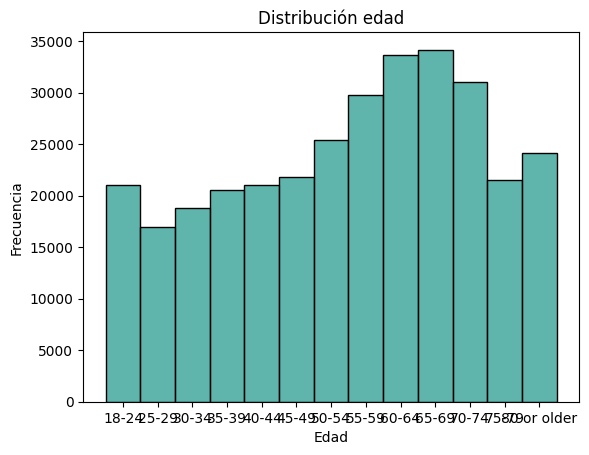

In [7]:
import seaborn as sns
df['AgeCategory'] = pd.Categorical(df['AgeCategory'], ['18-24','25-29','30-34','35-39','40-44','45-49','50-54','55-59','60-64','65-69','70-74','75-79','80 or older'])
plt.title('Distribución edad')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
sns.histplot(df['AgeCategory'],
             kde=False,
             color = '#2a9d8f'
             )


## 3.2. Distribución Enfermedades Cardiacas

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18876\1465077155.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df['HeartDisease'].value_counts().index,


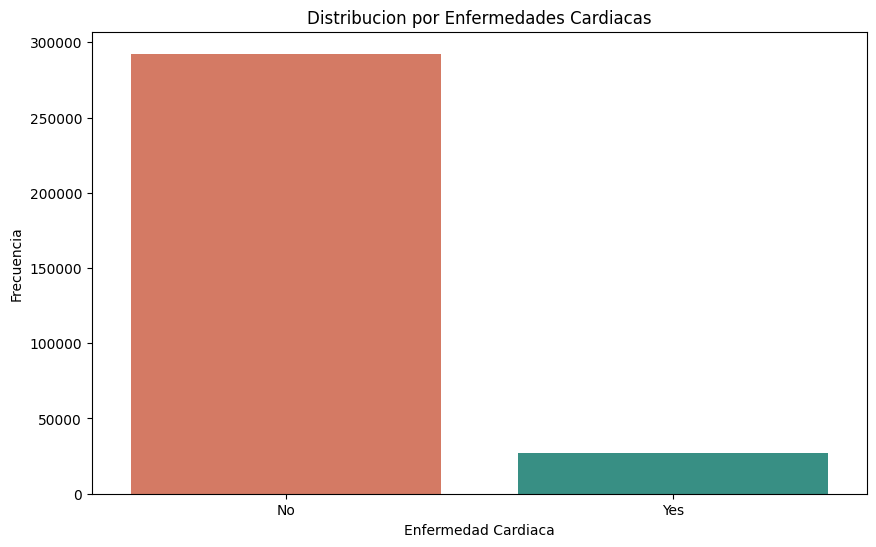

In [8]:
plt.figure(figsize=(10,6))
sns.barplot(x=df['HeartDisease'].value_counts().index,
            y=df['HeartDisease'].value_counts().values,
            palette=["#e76f51", "#2a9d8f"]
            )
plt.title('Distribucion por Enfermedades Cardiacas')
plt.xlabel('Enfermedad Cardiaca')
plt.ylabel('Frecuencia')
plt.show()

## 3.3. Distribución del Índice de Masa Corporal

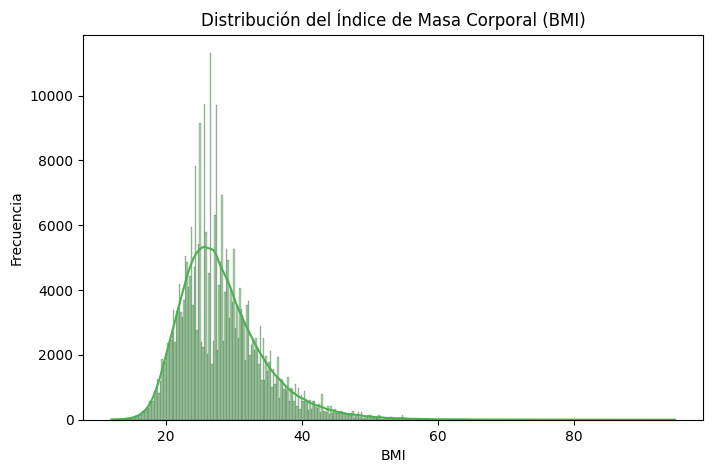

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(df['BMI'], kde=True, color='#4CAF50')
plt.title('Distribución del Índice de Masa Corporal (BMI)')
plt.xlabel('BMI')
plt.ylabel('Frecuencia')
plt.show()

## 3.4. Índice de Masa Corporal (BMI) según Enfermedad Cardíaca

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18876\589332420.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='HeartDisease', y='BMI', palette=['#2a9d8f', '#e76f51'])


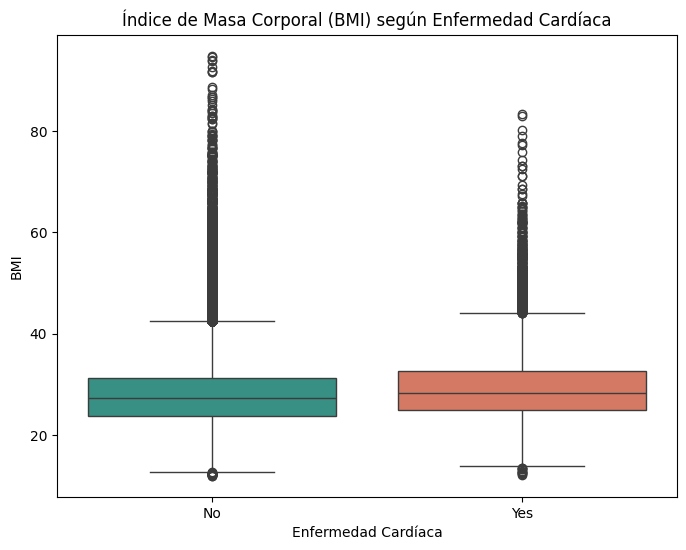

In [10]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x='HeartDisease', y='BMI', palette=['#2a9d8f', '#e76f51'])
plt.title('Índice de Masa Corporal (BMI) según Enfermedad Cardíaca')
plt.xlabel('Enfermedad Cardíaca')
plt.ylabel('BMI')
plt.show()

## 3.5. Relación entre Salud Física y Salud Mental

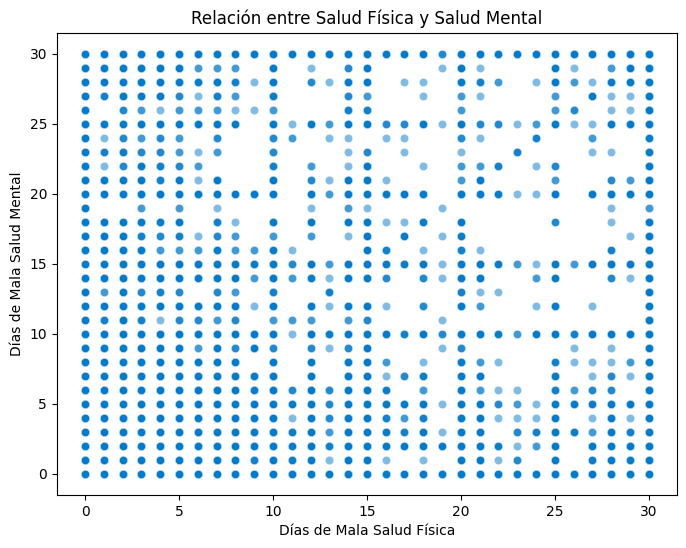

In [11]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='PhysicalHealth', y='MentalHealth', alpha=0.5, color='#007acc')
plt.title('Relación entre Salud Física y Salud Mental')
plt.xlabel('Días de Mala Salud Física')
plt.ylabel('Días de Mala Salud Mental')
plt.show()

## 3.6. Actividad Física según Sexo

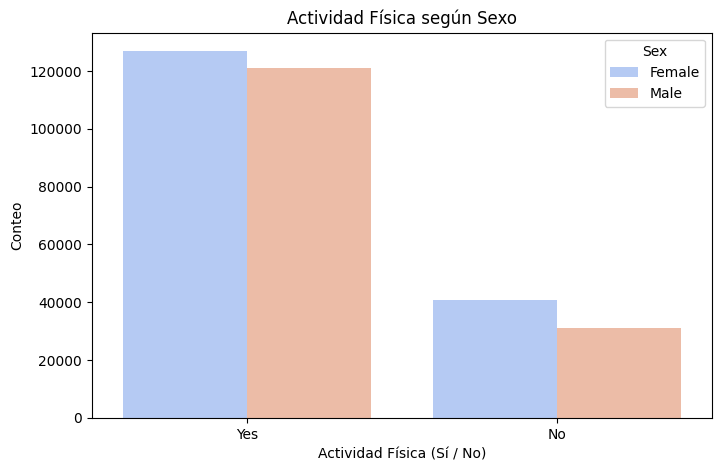

In [12]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='PhysicalActivity', hue='Sex', palette='coolwarm')
plt.title('Actividad Física según Sexo')
plt.xlabel('Actividad Física (Sí / No)')
plt.ylabel('Conteo')
plt.show()

## 3.7. Mapa de Calor de Correlación entre Variables Numéricas

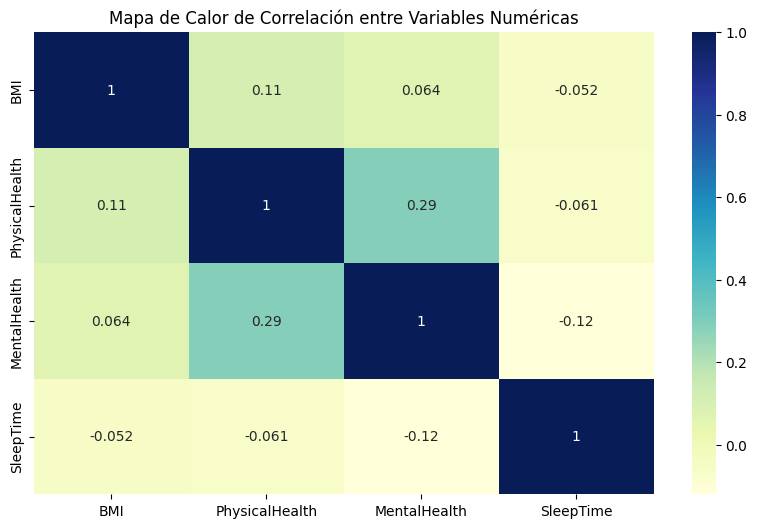

In [13]:
plt.figure(figsize=(10,6))
sns.heatmap(df[['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']].corr(), annot=True, cmap='YlGnBu')
plt.title('Mapa de Calor de Correlación entre Variables Numéricas')
plt.show()

## 3.9. Distribución de Enfermedad Cardíaca por Raza

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18876\3925788913.py:2: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.countplot(data=df_heart_disease, x='Race', hue='HeartDisease', palette=['#2a9d8f', '#e76f51'])


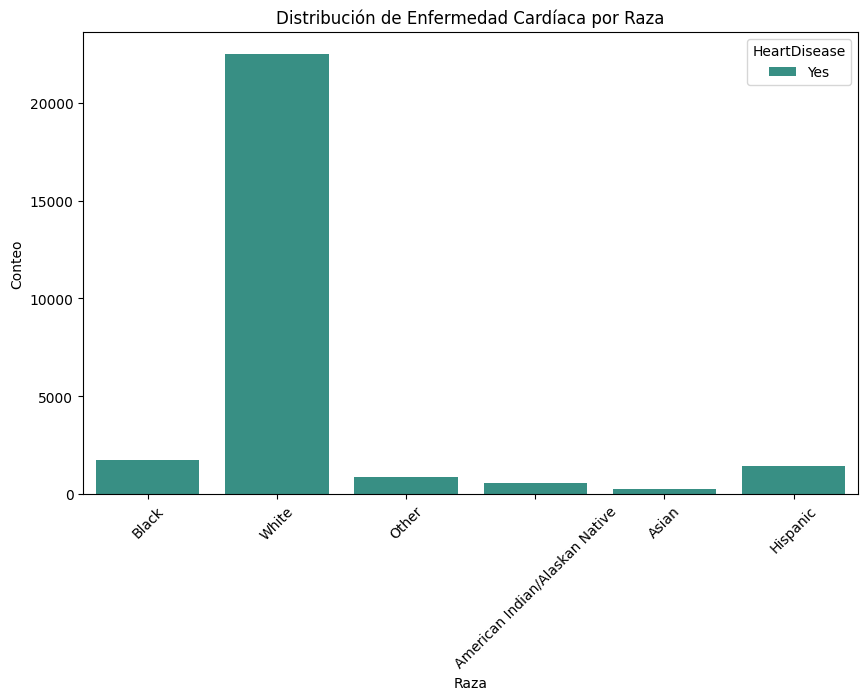

In [14]:
plt.figure(figsize=(10,6))
sns.countplot(data=df_heart_disease, x='Race', hue='HeartDisease', palette=['#2a9d8f', '#e76f51'])
plt.title('Distribución de Enfermedad Cardíaca por Raza')
plt.xlabel('Raza')
plt.ylabel('Conteo')
plt.xticks(rotation=45)
plt.show()

## 3.10. Distribución del Estado General de Salud

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18876\3830319835.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='GenHealth', palette='Blues')


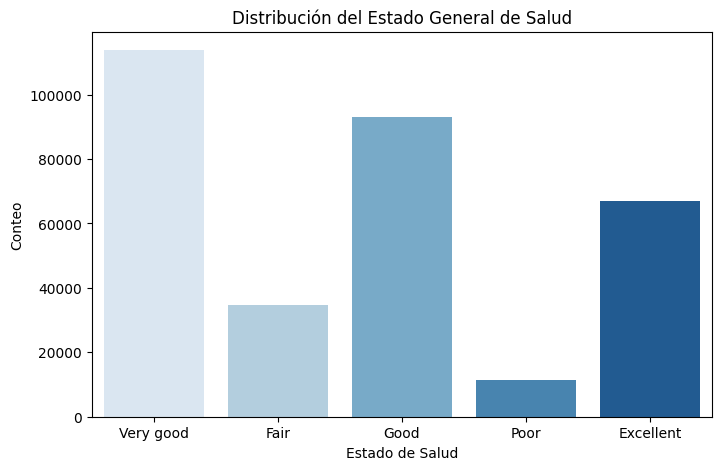

In [15]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='GenHealth', palette='Blues')
plt.title('Distribución del Estado General de Salud')
plt.xlabel('Estado de Salud')
plt.ylabel('Conteo')
plt.show()

## 3.11. Horas de Sueño según Categoría de Edad

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18876\3080392833.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='AgeCategory', y='SleepTime', palette='magma')


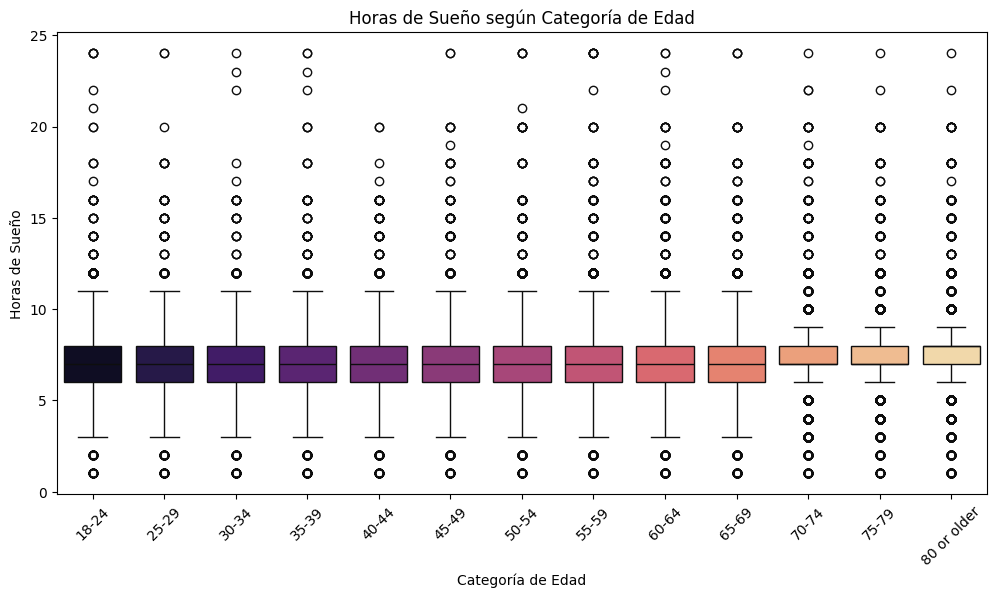

In [16]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='AgeCategory', y='SleepTime', palette='magma')
plt.title('Horas de Sueño según Categoría de Edad')
plt.xlabel('Categoría de Edad')
plt.ylabel('Horas de Sueño')
plt.xticks(rotation=45)
plt.show()

## 3.12. Relación entre Índice de Masa Corporal y Horas de Sueño

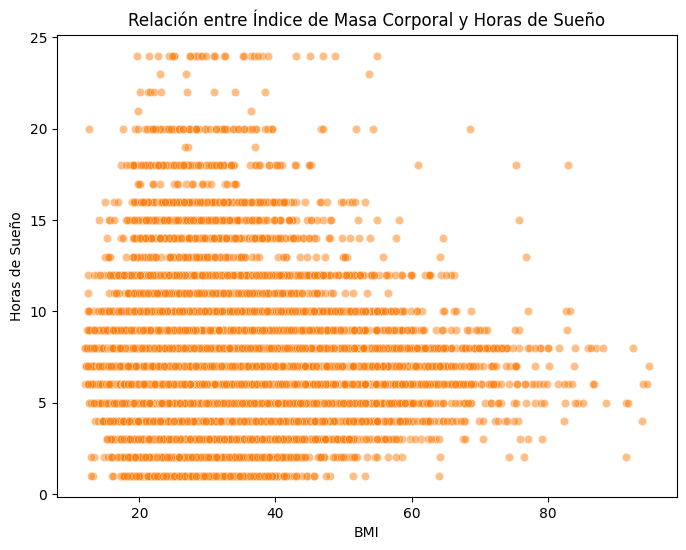

In [17]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='BMI', y='SleepTime', alpha=0.5, color='#FF7F0E')
plt.title('Relación entre Índice de Masa Corporal y Horas de Sueño')
plt.xlabel('BMI')
plt.ylabel('Horas de Sueño')
plt.show()

## 3.13. Proporción de Fumadores según Estado de Salud General

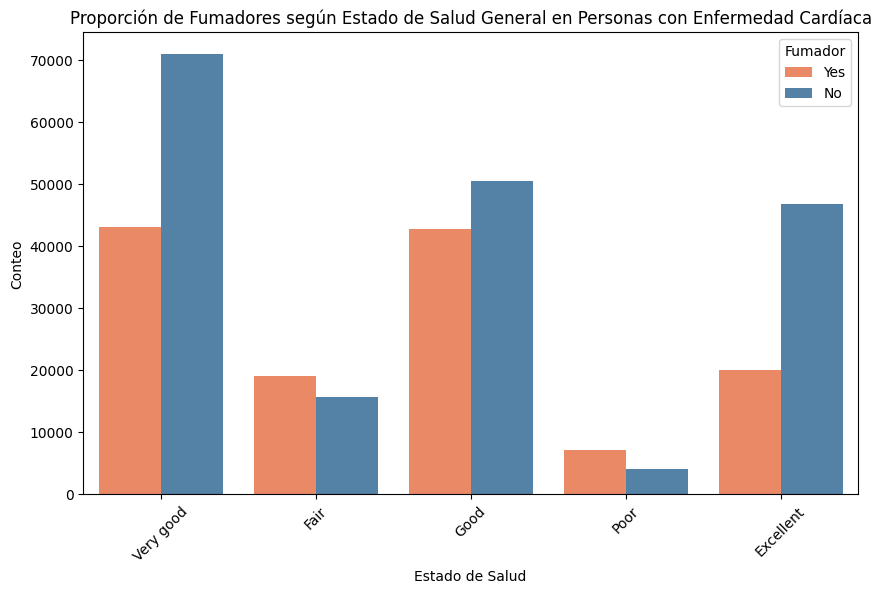

In [18]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, x='GenHealth', hue='Smoking', palette=['#FF7F50', '#4682B4'])
plt.title('Proporción de Fumadores según Estado de Salud General en Personas con Enfermedad Cardíaca')
plt.xlabel('Estado de Salud')
plt.ylabel('Conteo')
plt.xticks(rotation=45)
plt.legend(title='Fumador')
plt.show()

## 3.14. Distribución de Días de Mala Salud Mental según Sexo

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18876\201703802.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Sex', y='MentalHealth', palette='Set2')


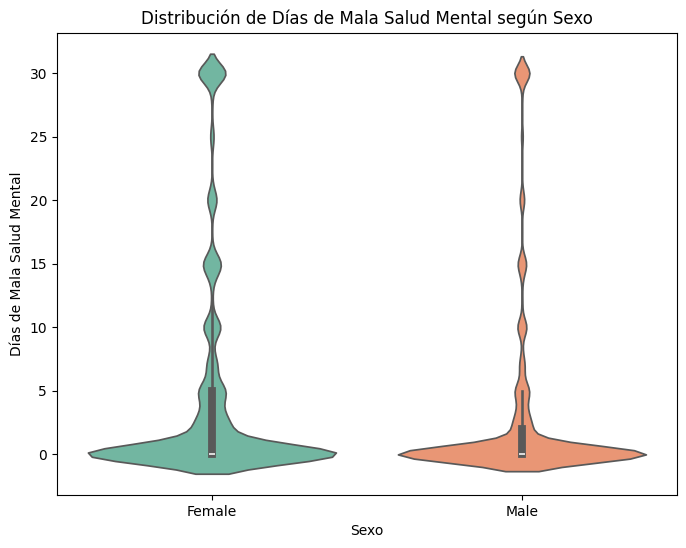

In [19]:
plt.figure(figsize=(8,6))
sns.violinplot(data=df, x='Sex', y='MentalHealth', palette='Set2')
plt.title('Distribución de Días de Mala Salud Mental según Sexo')
plt.xlabel('Sexo')
plt.ylabel('Días de Mala Salud Mental')
plt.show()

## 3.15. Frecuencia de Enfermedad Cardíaca por Raza

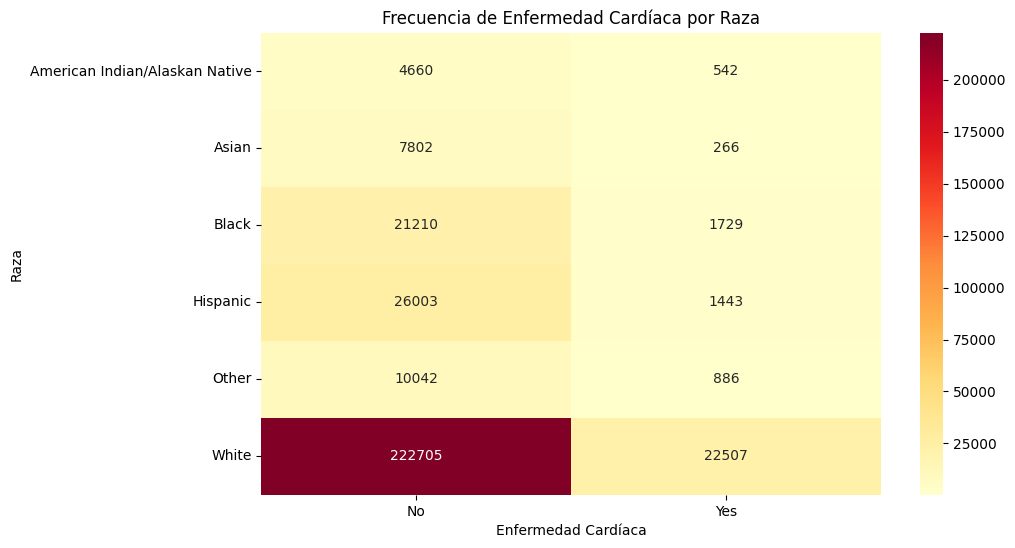

In [20]:
plt.figure(figsize=(10,6))
heatmap_data = df.groupby(['Race', 'HeartDisease']).size().unstack()
sns.heatmap(heatmap_data, annot=True, cmap='YlOrRd', fmt='d')
plt.title('Frecuencia de Enfermedad Cardíaca por Raza')
plt.xlabel('Enfermedad Cardíaca')
plt.ylabel('Raza')
plt.show()

## 3.16. Proporción de Fumadores según Enfermedad Cardíaca

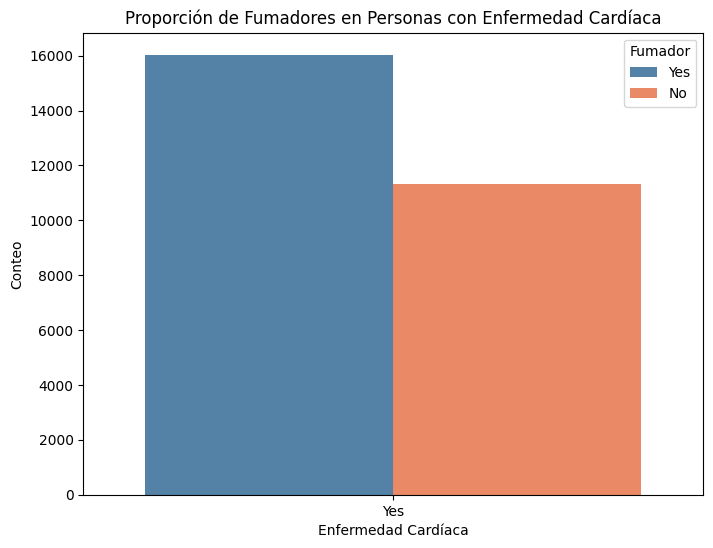

In [21]:
plt.figure(figsize=(8,6))
sns.countplot(data=df_heart_disease, x='HeartDisease', hue='Smoking', palette=['#4682B4', '#FF7F50'])
plt.title('Proporción de Fumadores en Personas con Enfermedad Cardíaca')
plt.xlabel('Enfermedad Cardíaca')
plt.ylabel('Conteo')
plt.legend(title='Fumador')
plt.show()

## 3.17. Consumo de Alcohol según Enfermedad Cardíaca

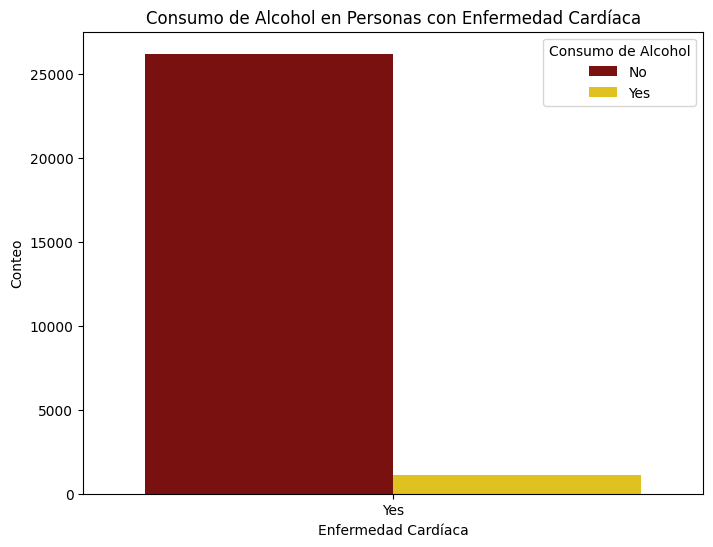

In [22]:
plt.figure(figsize=(8,6))
sns.countplot(data=df_heart_disease, x='HeartDisease', hue='AlcoholDrinking', palette=['#8B0000', '#FFD700'])
plt.title('Consumo de Alcohol en Personas con Enfermedad Cardíaca')
plt.xlabel('Enfermedad Cardíaca')
plt.ylabel('Conteo')
plt.legend(title='Consumo de Alcohol')
plt.show()

## 3.18. Días de Mala Salud Física según Enfermedad Cardíaca

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18876\3091518802.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='GenHealth', y='PhysicalHealth', palette='viridis')


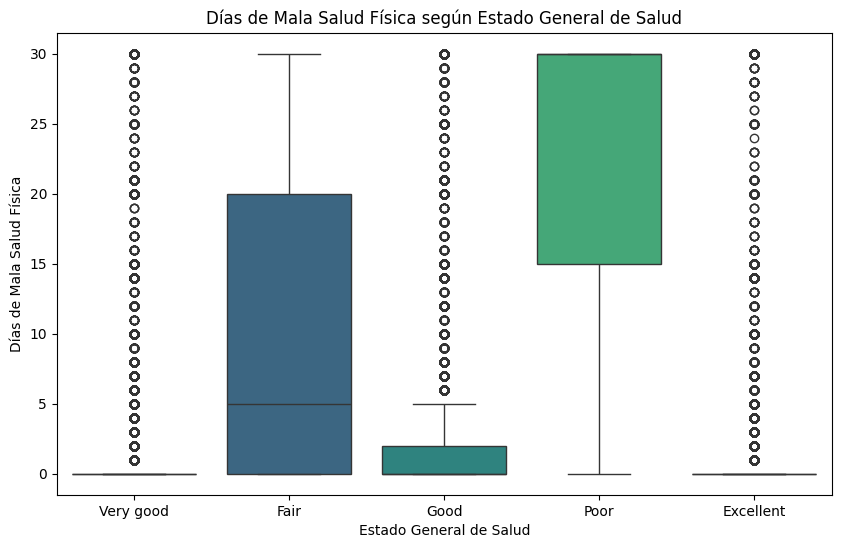

In [23]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='GenHealth', y='PhysicalHealth', palette='viridis')
plt.title('Días de Mala Salud Física según Estado General de Salud')
plt.xlabel('Estado General de Salud')
plt.ylabel('Días de Mala Salud Física')
plt.show()

## 3.19. Días de Mala Salud Mental según Enfermedad Cardíaca

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18876\1860634436.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='HeartDisease', y='MentalHealth', palette=['#2a9d8f', '#e76f51'])


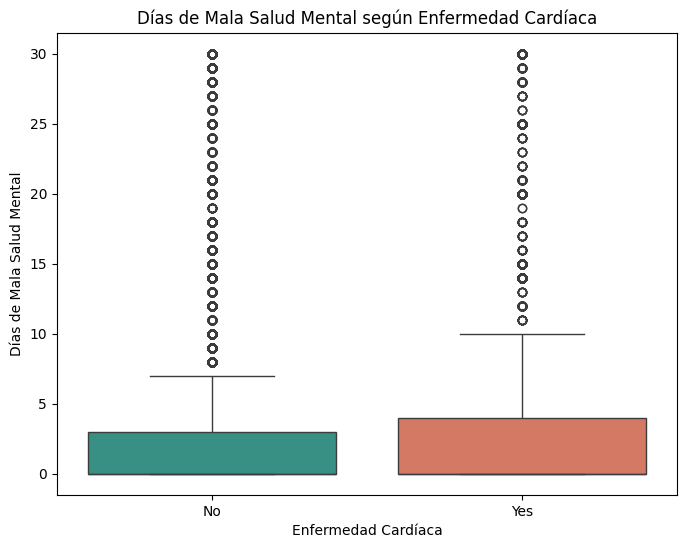

In [24]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x='HeartDisease', y='MentalHealth', palette=['#2a9d8f', '#e76f51'])
plt.title('Días de Mala Salud Mental según Enfermedad Cardíaca')
plt.xlabel('Enfermedad Cardíaca')
plt.ylabel('Días de Mala Salud Mental')
plt.show()

## 3.20. Actividad Física según Enfermedad Cardíaca

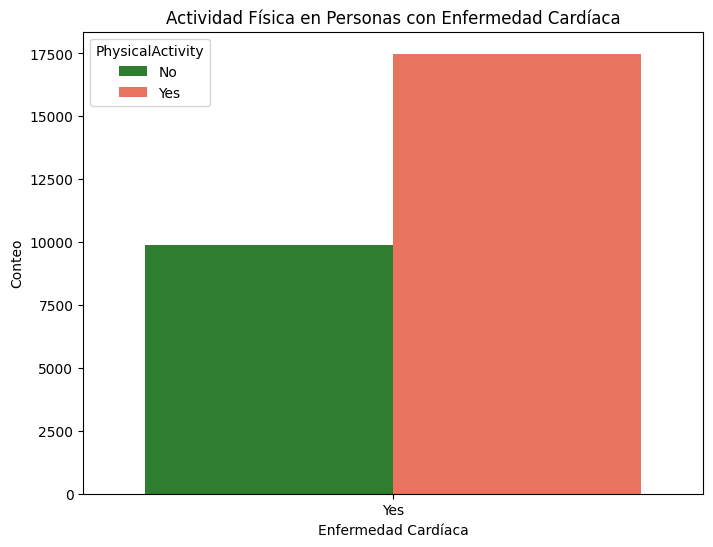

In [25]:
plt.figure(figsize=(8,6))
sns.countplot(data=df_heart_disease, x='HeartDisease', hue='PhysicalActivity', palette=['#228B22', '#FF6347'])
plt.title('Actividad Física en Personas con Enfermedad Cardíaca')
plt.xlabel('Enfermedad Cardíaca')
plt.ylabel('Conteo')
plt.show()

## 3.21. Estado General de Salud según Enfermedad Cardíaca

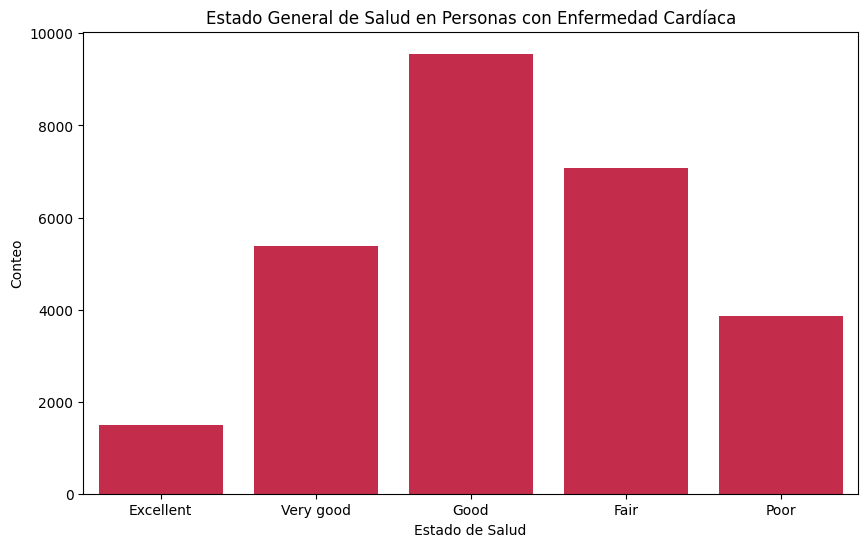

In [26]:
plt.figure(figsize=(10,6))
sns.countplot(data=df_heart_disease, x='GenHealth', color='#DC143C')
plt.title('Estado General de Salud en Personas con Enfermedad Cardíaca')
plt.xlabel('Estado de Salud')
plt.ylabel('Conteo')
plt.show()

## 3.22. Horas de Sueño según Enfermedad Cardíaca

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18876\3724850332.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='HeartDisease', y='SleepTime', palette=['#2a9d8f', '#e76f51'])


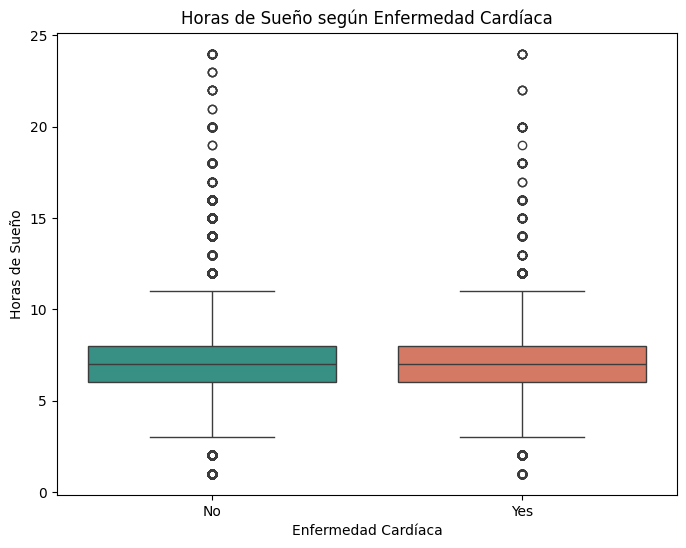

In [27]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x='HeartDisease', y='SleepTime', palette=['#2a9d8f', '#e76f51'])
plt.title('Horas de Sueño según Enfermedad Cardíaca')
plt.xlabel('Enfermedad Cardíaca')
plt.ylabel('Horas de Sueño')
plt.show()

## 3.23. Distribución de Enfermedad Cardíaca por Sexo

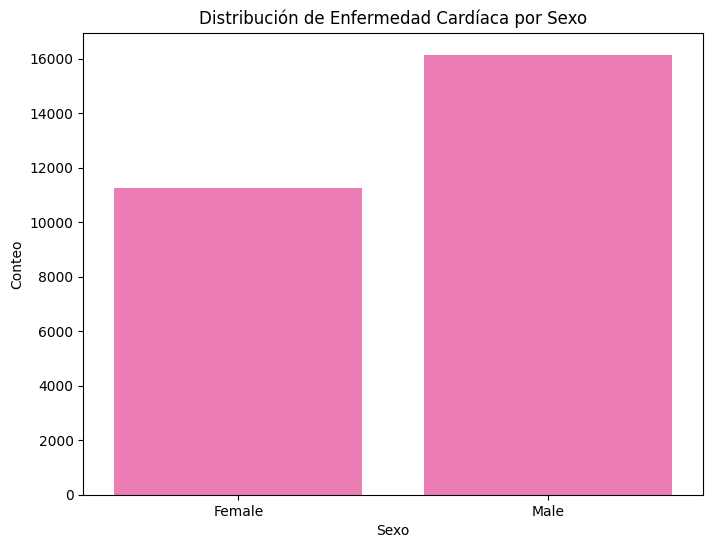

In [28]:
plt.figure(figsize=(8,6))
sns.countplot(data=df_heart_disease, x='Sex', color='#FF69B4')
plt.title('Distribución de Enfermedad Cardíaca por Sexo')
plt.xlabel('Sexo')
plt.ylabel('Conteo')
plt.show()

## 3.24. Distribución de Enfermedad Cardíaca por Raza

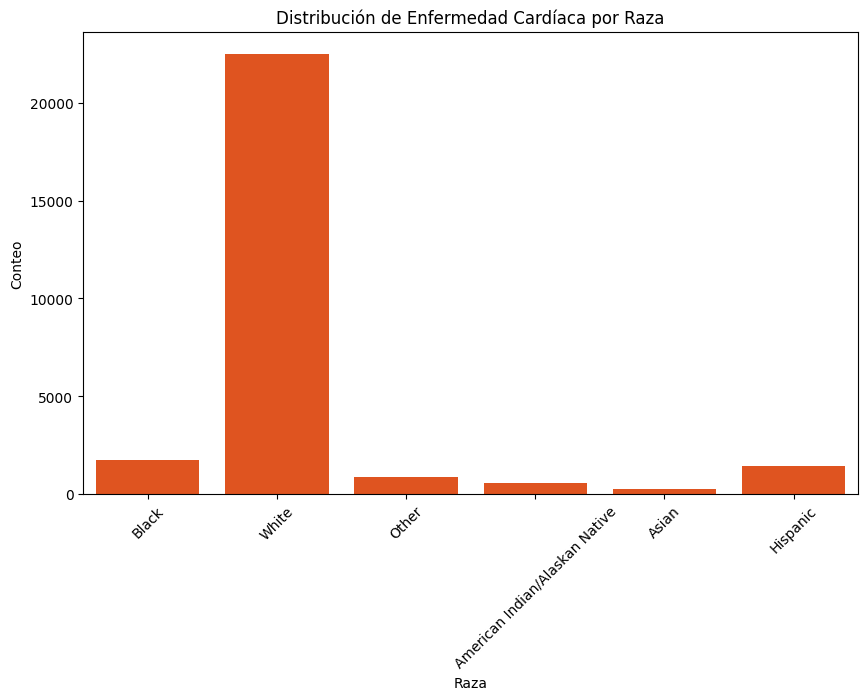

In [29]:
plt.figure(figsize=(10,6))
sns.countplot(data=df_heart_disease, x='Race', color='#FF4500')
plt.title('Distribución de Enfermedad Cardíaca por Raza')
plt.xlabel('Raza')
plt.ylabel('Conteo')
plt.xticks(rotation=45)
plt.show()

## 3.25. Distribución de Enfermedad Cardíaca por Categoría de Edad

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18876\760932238.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_heart_disease['AgeCategory'] = pd.Categorical(df_heart_disease['AgeCategory'], ['18-24','25-29','30-34','35-39','40-44','45-49','50-54','55-59','60-64','65-69','70-74','75-79','80 or older'])


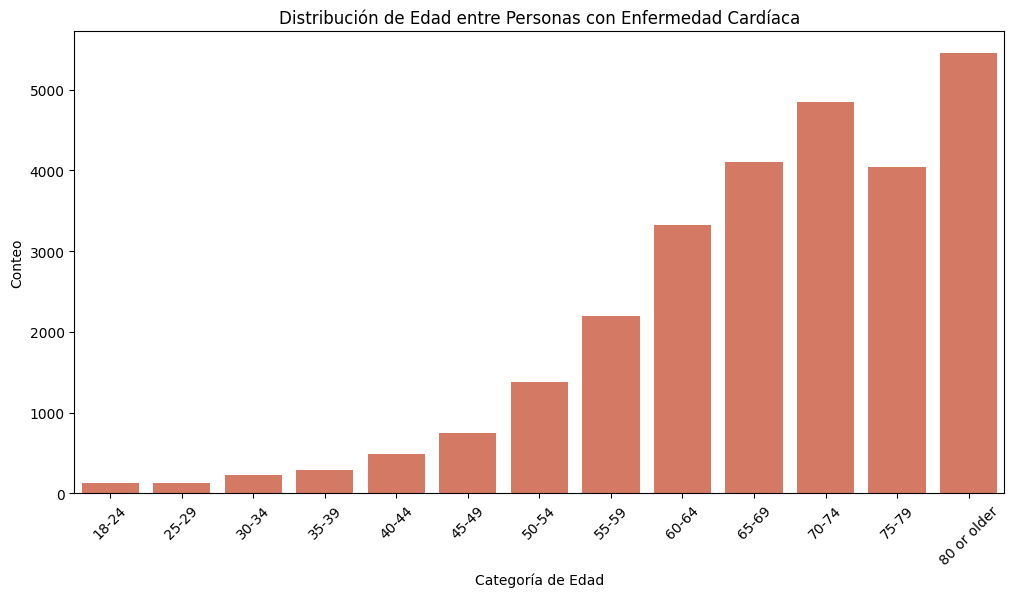

In [30]:
df_heart_disease['AgeCategory'] = pd.Categorical(df_heart_disease['AgeCategory'], ['18-24','25-29','30-34','35-39','40-44','45-49','50-54','55-59','60-64','65-69','70-74','75-79','80 or older'])
plt.figure(figsize=(12,6))
sns.countplot(data=df_heart_disease, x='AgeCategory', color='#e76f51')
plt.title('Distribución de Edad entre Personas con Enfermedad Cardíaca')
plt.xlabel('Categoría de Edad')
plt.ylabel('Conteo')
plt.xticks(rotation=45)
plt.show()

# 4. Preparar datos

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

## 4.1. Identificar las variables categoricas y numericas.

In [32]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer

bins = [0, 18.5, 24.9, 29.9, 34.9, 39.9, float('inf')]
labels = ['Underweight', 'Normal weight', 'Overweight', 'Obesity I', 'Obesity II', 'Obesity III']
df['BMI_Category'] = pd.cut(df['BMI'], bins=bins, labels=labels, right=False)
df['Diabetic'] = df['Diabetic'].replace({
    'No, borderline diabetes': 'No',
    'Yes (during pregnancy)': 'Yes'
})
df.drop(columns=['BMI','Sex'],inplace=True)

ordinal_cols = ['BMI_Category', 'AgeCategory', 'Race', 'GenHealth']
boolean_cols = ['HeartDisease', 'Smoking', 'AlcoholDrinking', 'Stroke', 'DiffWalking', 'Diabetic', 'PhysicalActivity', 'Asthma', 'KidneyDisease', 'SkinCancer']

ordinal_mappings = {
    'BMI_Category': ['Underweight', 'Normal weight', 'Overweight', 'Obesity I', 'Obesity II', 'Obesity III'],
    'AgeCategory': ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80 or older'],
    'Race': ['White', 'Black', 'Asian','Hispanic', 'American Indian/Alaskan Native', 'Other'],
    'GenHealth': ['Poor', 'Fair', 'Good', 'Very good', 'Excellent']
}
preprocessor = ColumnTransformer(
    transformers=[
        ('ord', OrdinalEncoder(categories=[ordinal_mappings[col] for col in ordinal_cols]), ordinal_cols),  # Ordinal encoding
        ('ohe', OneHotEncoder(drop='first'), boolean_cols)  # OneHotEncoding for boolean columns
    ],
    remainder='passthrough'
)

df_transformed = preprocessor.fit_transform(df)
ohe_columns = preprocessor.named_transformers_['ohe'].get_feature_names_out(boolean_cols)
final_columns = ordinal_cols + list(ohe_columns) + [col for col in df.columns if col not in ordinal_cols + boolean_cols]
df_encoded = pd.DataFrame(df_transformed, columns=final_columns)
preprocessor

c:\Users\Usuario\anaconda3\envs\py39\lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


ColumnTransformer(remainder='passthrough',
                  transformers=[('ord',
                                 OrdinalEncoder(categories=[['Underweight',
                                                             'Normal weight',
                                                             'Overweight',
                                                             'Obesity I',
                                                             'Obesity II',
                                                             'Obesity III'],
                                                            ['18-24', '25-29',
                                                             '30-34', '35-39',
                                                             '40-44', '45-49',
                                                             '50-54', '55-59',
                                                             '60-64', '65-69',
                                                             '70-74', '75-79',
                                                             '80 or older'],
                                                            ['White', 'Black',
                                                             'Asian',
                                                             'Hispanic',
                                                             'American '
                                                             'Indian/Alaskan '
                                                             'Native',
                                                             'Other'],
                                                            ['Poor', 'Fair',
                                                             'Good',
                                                             'Very good',
                                                             'Excellent']]),
                                 ['BMI_Category', 'AgeCategory', 'Race',
                                  'GenHealth']),
                                ('ohe', OneHotEncoder(drop='first'),
                                 ['HeartDisease', 'Smoking', 'AlcoholDrinking',
                                  'Stroke', 'DiffWalking', 'Diabetic',
                                  'PhysicalActivity', 'Asthma', 'KidneyDisease',
                                  'SkinCancer'])])

In [33]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319795 entries, 0 to 319794
Data columns (total 17 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   BMI_Category          319795 non-null  float64
 1   AgeCategory           319795 non-null  float64
 2   Race                  319795 non-null  float64
 3   GenHealth             319795 non-null  float64
 4   HeartDisease_Yes      319795 non-null  float64
 5   Smoking_Yes           319795 non-null  float64
 6   AlcoholDrinking_Yes   319795 non-null  float64
 7   Stroke_Yes            319795 non-null  float64
 8   DiffWalking_Yes       319795 non-null  float64
 9   Diabetic_Yes          319795 non-null  float64
 10  PhysicalActivity_Yes  319795 non-null  float64
 11  Asthma_Yes            319795 non-null  float64
 12  KidneyDisease_Yes     319795 non-null  float64
 13  SkinCancer_Yes        319795 non-null  float64
 14  PhysicalHealth        319795 non-null  float64
 15  

<Axes: >

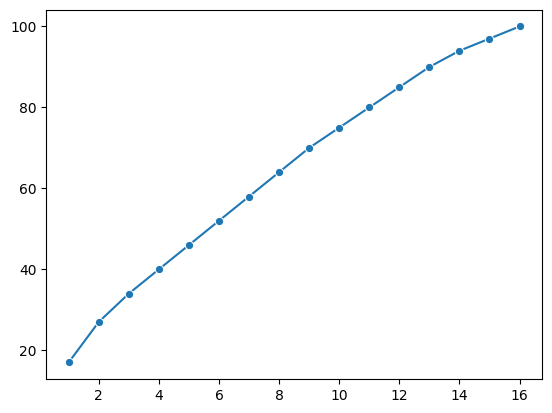

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df_encoded.drop('HeartDisease_Yes', axis=1)
y = df_encoded['HeartDisease_Yes']

scale = StandardScaler()
X_scaled= scale.fit_transform(X)

decom = PCA(svd_solver='auto')
X_pca = decom.fit_transform(X_scaled)
ex_var = np.cumsum(np.round(decom.explained_variance_ratio_, 2) * 100)
sns.lineplot(y=ex_var, x=np.arange(1, len(ex_var) + 1), marker='o')

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

## 4.2. Sampling

In [36]:
from imblearn.combine import SMOTEENN
smote_enn = SMOTEENN(random_state=42)
X_train_resampled, y_train_resampled = smote_enn.fit_resample(X_train, y_train)

c:\Users\Usuario\anaconda3\envs\py39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\Users\Usuario\anaconda3\envs\py39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\Users\Usuario\anaconda3\envs\py39\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the 

## 4.3. Función para contruir modelos

In [37]:
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    conf_matrix = confusion_matrix(y_test, y_pred)
    class_report = classification_report(y_test, y_pred)

    print(f'{model_name} Accuracy: {accuracy:.2f}')
    print(f'{model_name} Classification Report:\n{class_report}')

    disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=['No Heart Disease', 'Heart Disease'])
    disp.plot()
    plt.title(f'{model_name} Confusion Matrix')
    plt.show()

    return accuracy

# 5. Entrenar modelos

## 5.1. Logistic Regression

In [38]:
log_reg = LogisticRegression()
log_reg.fit(X_train_resampled, y_train_resampled)

LogisticRegression()

Logistic Regression Accuracy: 0.74
Logistic Regression Classification Report:
              precision    recall  f1-score   support

         0.0       0.97      0.74      0.84     58367
         1.0       0.22      0.76      0.34      5592

    accuracy                           0.74     63959
   macro avg       0.59      0.75      0.59     63959
weighted avg       0.90      0.74      0.80     63959



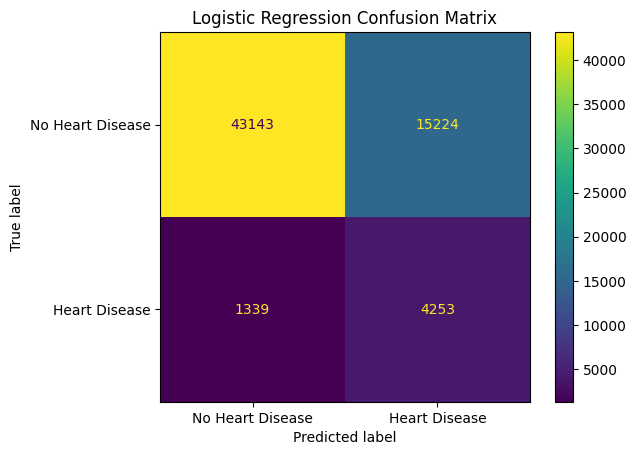

0.7410372269735299

In [39]:
log_reg_accuracy =evaluate_model(log_reg, X_test, y_test, 'Logistic Regression')
log_reg_accuracy

## 5.2. Random Forest Classifier

In [40]:
rf = RandomForestClassifier()
rf.fit(X_train_resampled, y_train_resampled)

RandomForestClassifier()

Random Forest Classifier Accuracy: 0.86
Random Forest Classifier Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      0.90      0.92     58367
         1.0       0.29      0.45      0.35      5592

    accuracy                           0.86     63959
   macro avg       0.62      0.67      0.64     63959
weighted avg       0.89      0.86      0.87     63959



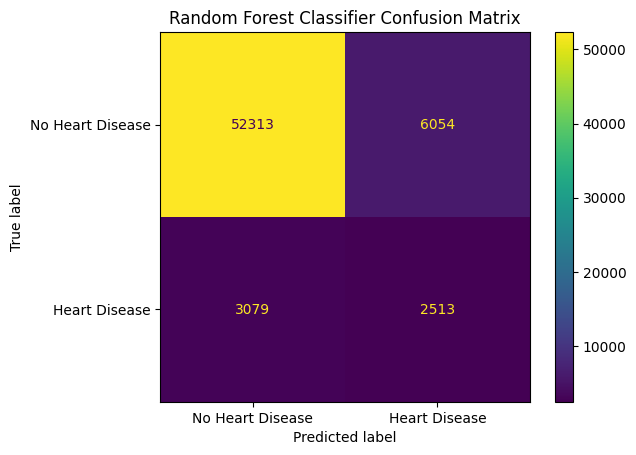

0.8572053972075862

In [41]:
rf_accuracy= evaluate_model(rf, X_test, y_test, 'Random Forest Classifier')
rf_accuracy

## 5.3. Gradient Boosting Classifier

In [42]:
gbc = GradientBoostingClassifier()
gbc.fit(X_train_resampled, y_train_resampled)

GradientBoostingClassifier()

Gradient Boosting Classifier Accuracy: 0.81
Gradient Boosting Classifier Classification Report:
              precision    recall  f1-score   support

         0.0       0.96      0.83      0.89     58367
         1.0       0.26      0.61      0.36      5592

    accuracy                           0.81     63959
   macro avg       0.61      0.72      0.63     63959
weighted avg       0.90      0.81      0.85     63959



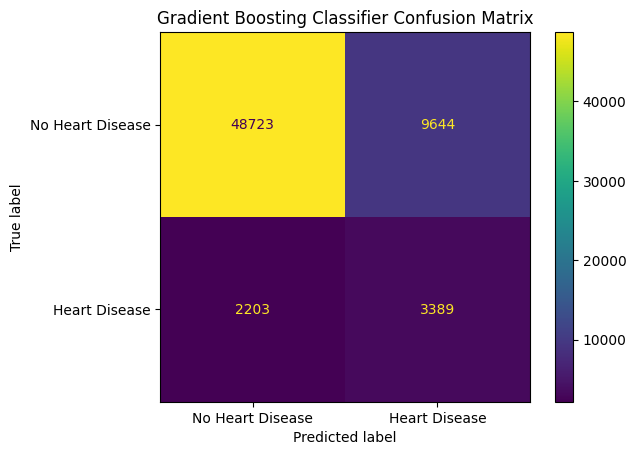

0.814771963288982

In [43]:
gbc_accuracy = evaluate_model(gbc, X_test, y_test, 'Gradient Boosting Classifier')
gbc_accuracy

## 5.4. Xgboost

In [44]:
import xgboost as xgb
xgboost_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')

xgboost_model.fit(X_train_resampled, y_train_resampled)

c:\Users\Usuario\anaconda3\envs\py39\lib\site-packages\xgboost\core.py:158: UserWarning: [13:16:58] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0c55ff5f71b100e98-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


AttributeError: 'super' object has no attribute '__sklearn_tags__'

AttributeError: 'super' object has no attribute '__sklearn_tags__'

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

XGBoost Classifier Accuracy: 0.88
XGBoost Classifier Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      0.93      0.93     58367
         1.0       0.34      0.40      0.37      5592

    accuracy                           0.88     63959
   macro avg       0.64      0.66      0.65     63959
weighted avg       0.89      0.88      0.89     63959



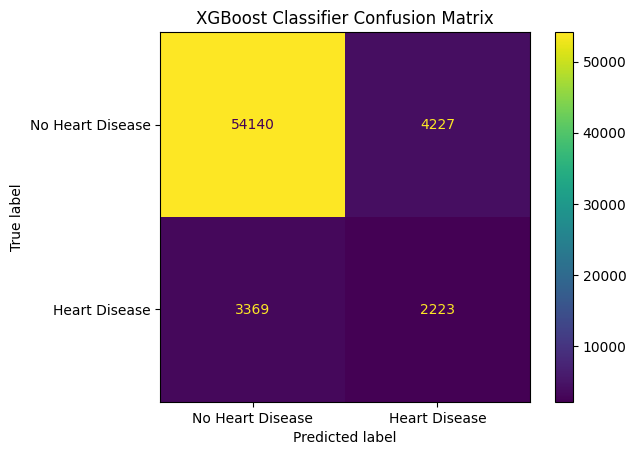

XGBoost Classifier Accuracy: 0.8812364170796917


In [45]:
xgboost_accuracy = evaluate_model(xgboost_model, X_test, y_test, 'XGBoost Classifier')
print(f'XGBoost Classifier Accuracy: {xgboost_accuracy}')

## 5.5. LightGBM

In [46]:
import lightgbm as lgb

lgbm_params = {
    'subsample': 0.95,
    'reg_lambda': 0.005623413251903491,
    'reg_alpha': 1.0,
    'num_leaves': 570,
    'n_estimators': 550,
    'min_data_in_leaf': 135,
    'min_child_weight': 0.02,
    'max_depth': 13,
    'learning_rate': 0.015,
    'feature_fraction': 0.85,
    'colsample_bytree': 0.9,
    'cat_smooth': 50,
    'bagging_freq': 9,
    'bagging_fraction': 0.85
}

lightgbm_model = lgb.LGBMClassifier(**lgbm_params, random_state=42, verbose=-1)
lightgbm_model.fit(X_train_resampled, y_train_resampled)

c:\Users\Usuario\anaconda3\envs\py39\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


LGBMClassifier(bagging_fraction=0.85, bagging_freq=9, cat_smooth=50,
               colsample_bytree=0.9, feature_fraction=0.85, learning_rate=0.015,
               max_depth=13, min_child_weight=0.02, min_data_in_leaf=135,
               n_estimators=550, num_leaves=570, random_state=42, reg_alpha=1.0,
               reg_lambda=0.005623413251903491, subsample=0.95, verbose=-1)

c:\Users\Usuario\anaconda3\envs\py39\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


LightGBM Classifier Accuracy: 0.88
LightGBM Classifier Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      0.92      0.93     58367
         1.0       0.34      0.41      0.37      5592

    accuracy                           0.88     63959
   macro avg       0.64      0.67      0.65     63959
weighted avg       0.89      0.88      0.88     63959



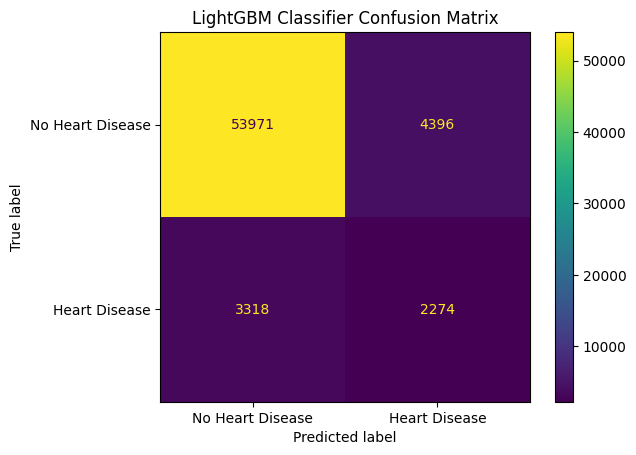

LightGBM Classifier Accuracy: 0.8793914851701872


In [47]:
lightgbm_accuracy = evaluate_model(lightgbm_model, X_test, y_test, 'LightGBM Classifier')
print(f'LightGBM Classifier Accuracy: {lightgbm_accuracy}')

## 5.6. Decision Tree Regressor

In [48]:
from sklearn.tree import DecisionTreeRegressor

dt_regressor = DecisionTreeRegressor()
dt_regressor.fit(X_train_resampled, y_train_resampled)

DecisionTreeRegressor()

Decision Tree Regressor Accuracy: 0.84
Decision Tree Regressor Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      0.89      0.91     58367
         1.0       0.25      0.39      0.30      5592

    accuracy                           0.84     63959
   macro avg       0.59      0.64      0.61     63959
weighted avg       0.88      0.84      0.86     63959



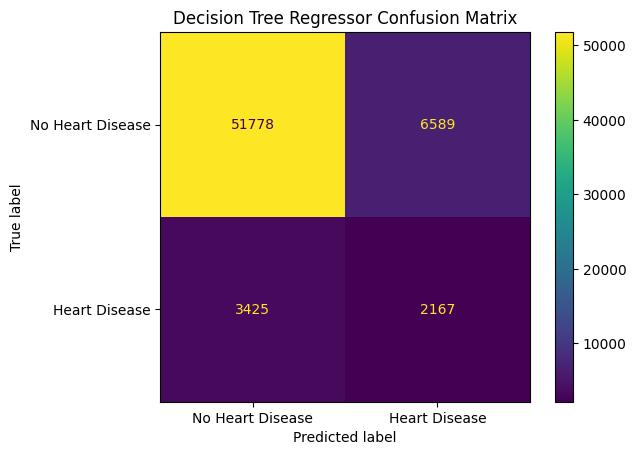

0.8434309479510311

In [49]:
dt_accuracy = evaluate_model(dt_regressor, X_test, y_test, 'Decision Tree Regressor')
dt_accuracy

## 5.7. KNeighbors Regressor

In [50]:
from sklearn.neighbors import KNeighborsRegressor

knn_regressor = KNeighborsRegressor()
knn_regressor.fit(X_train_resampled, y_train_resampled)

KNeighborsRegressor()

In [51]:
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error, r2_score
def evaluate_model_knn(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)

    # Check if the model is a regressor or classifier based on its type
    if isinstance(model, (DecisionTreeRegressor, KNeighborsRegressor)):  # Add other regressors here if used
        # For regression models, use metrics like MSE and R-squared
        mse = mean_squared_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        print(f'{model_name} - Mean Squared Error: {mse}')
        print(f'{model_name} - R-squared: {r2}')
        return mse  # or r2, depending on the preferred metric
    else:
        # For classification models, use accuracy and confusion matrix
        accuracy = accuracy_score(y_test, y_pred)
        conf_matrix = confusion_matrix(y_test, y_pred)
        print(f'{model_name} - Accuracy: {accuracy}')
        # Print or visualize confusion matrix as needed
        return accuracy

knn_accuracy = evaluate_model_knn(knn_regressor, X_test, y_test, 'K Neighbors Regressor')
knn_accuracy

K Neighbors Regressor - Mean Squared Error: 0.22215919573476758
K Neighbors Regressor - R-squared: -1.784409391999462


0.22215919573476758

## 5.8. Naive Bayes

In [52]:
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

GaussianNB()

In [53]:
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, confusion_matrix, classification_report
)

def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)

    # Detecta si es un modelo de regresión o clasificación
    if hasattr(model, "predict_proba") or len(set(y_test)) <= 2:
        # Clasificación
        accuracy = accuracy_score(y_test, y_pred)
        conf_matrix = confusion_matrix(y_test, y_pred)
        class_report = classification_report(y_test, y_pred)

        print(f"Resultados para {model_name}:")
        print(f"Exactitud (Accuracy): {accuracy}")
        print("Matriz de Confusión:")
        print(conf_matrix)
        print("Reporte de Clasificación:")
        print(class_report)

        return accuracy
    else:
        # Regresión
        mse = mean_squared_error(y_test, y_pred)
        mae = mean_absolute_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)

        print(f"Resultados para {model_name}:")
        print(f"Error Cuadrático Medio (MSE): {mse}")
        print(f"Error Absoluto Medio (MAE): {mae}")
        print(f"Puntaje R^2: {r2}")

        return r2

# Evaluar el modelo
nb_accuracy = evaluate_model(nb_model, X_test, y_test, 'Naive Bayes')
print(f"Exactitud de Naive Bayes: {nb_accuracy}")

Resultados para Naive Bayes:
Exactitud (Accuracy): 0.8389280632905455
Matriz de Confusión:
[[51002  7365]
 [ 2937  2655]]
Reporte de Clasificación:
              precision    recall  f1-score   support

         0.0       0.95      0.87      0.91     58367
         1.0       0.26      0.47      0.34      5592

    accuracy                           0.84     63959
   macro avg       0.61      0.67      0.62     63959
weighted avg       0.89      0.84      0.86     63959

Exactitud de Naive Bayes: 0.8389280632905455


## 5.9. Support Vector Machine (SVM)

In [54]:
from sklearn.svm import LinearSVC  # Para clasificación
from sklearn.calibration import CalibratedClassifierCV

svm_model = LinearSVC()
svm_model = CalibratedClassifierCV(svm_model)  # Para obtener probabilidades
svm_model.fit(X_train, y_train)

CalibratedClassifierCV(estimator=LinearSVC())

In [55]:
svm_accuracy = evaluate_model(svm_model, X_test, y_test, 'Support Vector Machines (SVM)')
svm_accuracy

Resultados para Support Vector Machines (SVM):
Exactitud (Accuracy): 0.9131318500914648
Matriz de Confusión:
[[57771   596]
 [ 4960   632]]
Reporte de Clasificación:
              precision    recall  f1-score   support

         0.0       0.92      0.99      0.95     58367
         1.0       0.51      0.11      0.19      5592

    accuracy                           0.91     63959
   macro avg       0.72      0.55      0.57     63959
weighted avg       0.89      0.91      0.89     63959



0.9131318500914648

## 5.10. Redes Neuronales Artificiales (ANN)

In [57]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Construyendo un modelo ANN
ann_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')  # Cambia según el problema (regresión/clasificación)
])

# Compilación y entrenamiento
ann_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
ann_model.fit(X_train, y_train, epochs=20, batch_size=32, verbose=1)

Epoch 1/20


c:\Users\Usuario\anaconda3\envs\py39\lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7995/7995 ━━━━━━━━━━━━━━━━━━━━ 8s 912us/step - accuracy: 0.9146 - loss: 0.2389
Epoch 2/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - accuracy: 0.9157 - loss: 0.2286   
Epoch 3/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 8s 990us/step - accuracy: 0.9158 - loss: 0.2288
Epoch 4/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 882us/step - accuracy: 0.9164 - loss: 0.2284
Epoch 5/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 6s 798us/step - accuracy: 0.9157 - loss: 0.2283
Epoch 6/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 6s 802us/step - accuracy: 0.9173 - loss: 0.2259
Epoch 7/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 6s 808us/step - accuracy: 0.9158 - loss: 0.2279
Epoch 8/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 830us/step - accuracy: 0.9159 - loss: 0.2286
Epoch 9/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 6s 803us/step - accuracy: 0.9168 - loss: 0.2267
Epoch 10/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 6s 799us/step - accuracy: 0.9166 - loss: 0.2260
Epoch 11/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 6s 796us/step - accuracy: 0.9167 - loss: 0.2260
Epoch 12/20
7995/7

In [59]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

def evaluate_model(model, X_test, y_test, model_name):
    # Realiza las predicciones
    y_pred_proba = model.predict(X_test)
    y_pred = (y_pred_proba > 0.5).astype(int)  # Convierte las predicciones continuas en binarias

    # Detecta si es un modelo de regresión o clasificación
    if hasattr(model, "predict_proba") or len(set(y_test)) <= 2:
        # Clasificación
        accuracy = accuracy_score(y_test, y_pred)
        conf_matrix = confusion_matrix(y_test, y_pred)
        class_report = classification_report(y_test, y_pred)
        print(f"{model_name} Accuracy: {accuracy}")
        print(f"{model_name} Confusion Matrix:\n{conf_matrix}")
        print(f"{model_name} Classification Report:\n{class_report}")
    else:
        # Regresión
        mse = mean_squared_error(y_test, y_pred)
        print(f"{model_name} Mean Squared Error: {mse}")

    return accuracy

# Evaluación
ann_accuracy = evaluate_model(ann_model, X_test, y_test, 'Artificial Neural Network')
ann_accuracy

1999/1999 ━━━━━━━━━━━━━━━━━━━━ 1s 450us/step
Artificial Neural Network Accuracy: 0.9126627996059976
Artificial Neural Network Confusion Matrix:
[[57919   448]
 [ 5138   454]]
Artificial Neural Network Classification Report:
              precision    recall  f1-score   support

         0.0       0.92      0.99      0.95     58367
         1.0       0.50      0.08      0.14      5592

    accuracy                           0.91     63959
   macro avg       0.71      0.54      0.55     63959
weighted avg       0.88      0.91      0.88     63959



0.9126627996059976

## 5.11. Redes Recurrentes (RNN)

In [61]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
import numpy as np

# Asegúrate de que X_train tenga la forma correcta
X_train_rnn = np.expand_dims(X_train, axis=1)  # Agrega una dimensión para los timesteps

# Construyendo una RNN
rnn_model = Sequential([
    SimpleRNN(50, activation='tanh', input_shape=(X_train_rnn.shape[1], X_train_rnn.shape[2])),
    Dense(1, activation='linear')  # Para regresión
])

# Compilación y entrenamiento
rnn_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
rnn_model.fit(X_train_rnn, y_train, epochs=20, batch_size=32, verbose=1)

Epoch 1/20


c:\Users\Usuario\anaconda3\envs\py39\lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7995/7995 ━━━━━━━━━━━━━━━━━━━━ 8s 876us/step - loss: 0.0850 - mae: 0.1672
Epoch 2/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 828us/step - loss: 0.0679 - mae: 0.1418
Epoch 3/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 842us/step - loss: 0.0672 - mae: 0.1378
Epoch 4/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 829us/step - loss: 0.0661 - mae: 0.1348
Epoch 5/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 849us/step - loss: 0.0666 - mae: 0.1358
Epoch 6/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 854us/step - loss: 0.0667 - mae: 0.1354
Epoch 7/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 831us/step - loss: 0.0665 - mae: 0.1350
Epoch 8/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 829us/step - loss: 0.0665 - mae: 0.1349
Epoch 9/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 826us/step - loss: 0.0662 - mae: 0.1340
Epoch 10/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 874us/step - loss: 0.0659 - mae: 0.1336
Epoch 11/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 836us/step - loss: 0.0663 - mae: 0.1343
Epoch 12/20
7995/7995 ━━━━━━━━━━━━━━━━━━━━ 7s 835us/step - loss: 0.0657 - 

In [63]:
# Asegúrate de que X_test tenga la forma correcta
X_test_rnn = np.expand_dims(X_test, axis=1)  # Agrega una dimensión para los timesteps

# Evaluación
rnn_accuracy = evaluate_model(rnn_model, X_test_rnn, y_test, 'Recurrent Neural Network')
rnn_accuracy

1999/1999 ━━━━━━━━━━━━━━━━━━━━ 1s 565us/step
Recurrent Neural Network Accuracy: 0.9138354258196657
Recurrent Neural Network Confusion Matrix:
[[58171   196]
 [ 5315   277]]
Recurrent Neural Network Classification Report:
              precision    recall  f1-score   support

         0.0       0.92      1.00      0.95     58367
         1.0       0.59      0.05      0.09      5592

    accuracy                           0.91     63959
   macro avg       0.75      0.52      0.52     63959
weighted avg       0.89      0.91      0.88     63959



0.9138354258196657

## 5.12. Modelos de Clustering (K-Means)

In [73]:
from sklearn.cluster import KMeans
kmeans_model = KMeans(n_clusters=3, random_state=42)
kmeans_model.fit(X_train)
# Predicciones y evaluación
kmeans_predictions = kmeans_model.predict(X_test)

In [75]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

def evaluate_clustering(predictions, true_labels, model_name):
    # Calcula las métricas de evaluación
    ari = adjusted_rand_score(true_labels, predictions)
    nmi = normalized_mutual_info_score(true_labels, predictions)
    
    print(f"{model_name} Adjusted Rand Index: {ari}")
    print(f"{model_name} Normalized Mutual Information: {nmi}")
    
    return ari, nmi

# Supongamos que kmeans_predictions contiene las predicciones del modelo K-Means
# y_test contiene las etiquetas verdaderas
kmeans_accuracy = evaluate_clustering(kmeans_predictions, y_test, 'K-Means')
kmeans_accuracy

K-Means Adjusted Rand Index: 0.11991245853412622
K-Means Normalized Mutual Information: 0.05029591770486969


(0.11991245853412622, np.float64(0.05029591770486969))

## 5.13. Reduccion de Dimensionalidad (PCA)

In [77]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

# Supongamos que ya has ajustado un modelo PCA
pca_model = PCA(n_components=2)
X_train_pca = pca_model.fit_transform(X_train)
X_test_pca = pca_model.transform(X_test)

# Aplicar un modelo después de PCA
lr_pca_model = LinearRegression()
lr_pca_model.fit(X_train_pca, y_train)

# Evaluación
y_pred = lr_pca_model.predict(X_test_pca)

In [79]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_squared_error

def evaluate_model(model, X_test, y_test, model_name):
    # Realiza las predicciones
    y_pred = model.predict(X_test)

    # Detecta si es un modelo de regresión o clasificación
    if hasattr(model, "predict_proba") or len(set(y_test)) <= 2:
        # Clasificación
        y_pred_classes = np.argmax(y_pred, axis=1) if y_pred.ndim > 1 else (y_pred > 0.5).astype(int)
        accuracy = accuracy_score(y_test, y_pred_classes)
        conf_matrix = confusion_matrix(y_test, y_pred_classes)
        class_report = classification_report(y_test, y_pred_classes)
        print(f"{model_name} Accuracy: {accuracy}")
        print(f"{model_name} Confusion Matrix:\n{conf_matrix}")
        print(f"{model_name} Classification Report:\n{class_report}")
        return accuracy
    else:
        # Regresión
        mse = mean_squared_error(y_test, y_pred)
        print(f"{model_name} Mean Squared Error: {mse}")
        return mse

# Evaluación
lr_pca_accuracy = evaluate_model(lr_pca_model, X_test_pca, y_test, 'PCA with Linear Regression')
lr_pca_accuracy

PCA with Linear Regression Accuracy: 0.9127253396707266
PCA with Linear Regression Confusion Matrix:
[[58354    13]
 [ 5569    23]]
PCA with Linear Regression Classification Report:
              precision    recall  f1-score   support

         0.0       0.91      1.00      0.95     58367
         1.0       0.64      0.00      0.01      5592

    accuracy                           0.91     63959
   macro avg       0.78      0.50      0.48     63959
weighted avg       0.89      0.91      0.87     63959



0.9127253396707266

## 5.14. Markov Models (HMM)

In [81]:
from hmmlearn.hmm import GaussianHMM

# Configuración del modelo
hmm_model = GaussianHMM(n_components=4, covariance_type="diag", n_iter=100)
hmm_model.fit(X_train)

GaussianHMM(n_components=4, n_iter=100)

In [89]:
from sklearn.metrics import accuracy_score

# Predicciones
hmm_predictions = hmm_model.predict(X_test)

# Calcular la precisión
hmm_accuracy = accuracy_score(y_test, hmm_predictions)
print(f'Accuracy of the test set: {hmm_accuracy}')

Accuracy of the test set: 0.7019496865179256


## 6. Resultados

In [92]:
# Supongamos que ya has calculado la precisión para el modelo HMM
hmm_accuracy = accuracy_score(y_test, hmm_predictions)

algorithms = ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost Classifier', 'LightGBM Classifier',
              'Decision Tree Regressor', 'KNeighbors Regressor', 'Naive Bayes', 'Support Vector Machines (SVM)', 
              'Artificial Neural Network', 'Recurrent Neural Network', 'K-Means', 'PCA', 'Markov models']
accuracies = [log_reg_accuracy * 100, rf_accuracy * 100, gbc_accuracy * 100, xgboost_accuracy * 100,
              lightgbm_accuracy * 100, dt_accuracy * 100, knn_accuracy * 100, nb_accuracy * 100, svm_accuracy * 100, 
              ann_accuracy * 100, rnn_accuracy * 100, kmeans_accuracy[0] * 100, lr_pca_accuracy * 100, hmm_accuracy * 100]

# Crear el DataFrame
results_df = pd.DataFrame({'Algorithms': algorithms, 'Accuracies': accuracies})

# Ordenar el DataFrame de mayor a menor precisión
results_df = results_df.sort_values(by='Accuracies', ascending=False)

# Formatear las precisiones como porcentajes
results_df['Accuracies'] = results_df['Accuracies'].apply(lambda x: f'{x:.2f}%')

print(results_df)

                       Algorithms Accuracies
10       Recurrent Neural Network     91.38%
8   Support Vector Machines (SVM)     91.31%
12                            PCA     91.27%
9       Artificial Neural Network     91.27%
3              XGBoost Classifier     88.12%
4             LightGBM Classifier     87.94%
1                   Random Forest     85.72%
5         Decision Tree Regressor     84.34%
7                     Naive Bayes     83.89%
2               Gradient Boosting     81.48%
0             Logistic Regression     74.10%
13                  Markov models     70.19%
6            KNeighbors Regressor     22.22%
11                        K-Means     11.99%
